# Quantized Leaf Radiance Reconstruction

## 1. Problem

Can spatial regularity recover within-bin color and shading from only six-level interval measurements? This notebook actively reconstructs the complete native RGB leaf image using local executable TV and second-order TGV mathematics. The true pre-quantization photograph is used only for maintainer evaluation. It is never read by a reconstruction function.

The selected method is Bredies' multichannel TGV dequantization (2014 chapter; author April2012 preprint, Section4.4). The selected author's source includes a midpoint fidelity term as well as interval constraints. Removing that term changes the problem. We retain TV and TGV, and the original example's eleven regularization settings; all fresh plotted methods below are actually computed.

## 2. Data

The source includes Stephen Heron's real 512×512 oak-leaf photograph under CC-BY-SA2.0. The author-defined observation protocol computes `lower=floor(6*image)/6` and `upper=ceil(6*image)/6` using float32. These are **new simulated quantization observations of an author-provided real photograph**, not measurements from a coarse-bit detector. No additional noise or crop is introduced. Samples exactly on a quantization boundary have identical endpoints.

Public observations contain only the two (1,512,512,3) float32 interval arrays. Intensities are dimensionless encoded camera values; no absolute radiometric calibration is claimed. Maintainer truth is the original photograph. Original-source TV/TGV outputs are separately identified numerical references, not truth.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import torch,matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct_tensor,reconstruct,objective
from src.physics_model import gradient,vector_norm
from src.visualization import metrics,image_panel
lower,upper=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False) as f:truth=f['reconstruction'][0]
with np.load(ROOT/'notebooks/reference_outputs/upstream_outputs.npz',allow_pickle=False) as f:original={k:f[k].copy() for k in f.files}
with np.load(ROOT/'output/reconstruction.npz',allow_pickle=False) as f:standard_cpu=f['reconstruction'][0].copy()
midpoint=.5*(lower+upper)
device='cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(1)
print(json.dumps({'python':sys.executable,'numpy':np.__version__,'torch':torch.__version__,'device':device,'gpu':torch.cuda.get_device_name(0) if device=='cuda' else None,'backend':matplotlib.get_backend(),'shape':lower.shape,'dtype':str(lower.dtype)},indent=2))
figures=[];numbers={'lower':lower,'upper':upper,'truth':truth,'midpoint':midpoint,'standard_cpu':standard_cpu}
def show(fig,name):
    figures.append((name,fig));display(fig);plt.close(fig)


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "torch": "2.9.1+cu128",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 4080 SUPER",
  "backend": "inline",
  "shape": [
    512,
    512,
    3
  ],
  "dtype": "float32"
}


## 3. Physics

For pixel $p$, RGB channel $c$ and bin count $B=6$, acquisition retains only

$$
l(p,c)=\lfloor Bu(p,c)\rfloor/B,\qquad h(p,c)=\lceil Bu(p,c)\rceil/B.
$$

Here $u$ is unknown encoded intensity and $l,h$ are measured bounds. The feasible set is an interval at each pixel/channel. Its midpoint is $m=(l+h)/2$. Every reconstructed intensity must remain inside that interval. Spatial recovery relies on a prior, so fine structure irreversibly lost to quantization cannot be guaranteed.

The forward difference $D$ uses unit pixel spacing and zero outgoing derivatives at the bottom and right edges. Its divergence is the **negative adjoint**. For the two-component field $v$, the symmetric derivative is $Ev=(D_1v_1,D_2v_2,(D_2v_1+D_1v_2)/2)$. The symmetric-tensor inner product counts the cross component twice. These are computational coordinates; no physical leaf length is available.

## 4. Method

For positive weights $\alpha_1=0.45$ and $\alpha_0=2\alpha_1$, solve the source's discrete objective

$$
\min_{l\le u\le h,v}\ \tfrac12\sum_{p,c}(u-m)^2+
\alpha_1\sum_p\|Du-v\|_2+\alpha_0\sum_p\|Ev\|_F.
$$

Norms couple all RGB channels and spatial components at each pixel; $\|\cdot\|_F$ is the symmetric Frobenius norm. The TV comparison omits $v$ and the second-order term. There is no division by pixel count or hidden scale change.

Let $a,b$ be the first- and second-order dual fields, and barred quantities be extrapolated primal fields. Each iteration projects $a+\sigma(D\bar u-\bar v)$ onto the radius-$\alpha_1$ Euclidean ball and $b+\sigma E\bar v$ onto the radius-$\alpha_0$ Frobenius ball. With $\mathrm{div}=-D^*$ and $\mathrm{div}_s=-E^*$, the primal updates are

$$
u^+=\mathrm{clip}_{[l,h]}\left(m+\frac{u+\tau\mathrm{div}(a)-m}{1+\tau}\right),\qquad
v^+=v+\tau(a+\mathrm{div}_s b).
$$

The extrapolation is twice the new primal minus the old primal. Initialization is $u=m$ and all other fields zero. TV uses $\tau=\sigma=1/\sqrt8$, TGV uses $1/\sqrt{12}$; both run the original fixed2000 updates. No convergence claim is inferred from that budget. NumPy CPU and general PyTorch tensor implementations use the same explicit mathematics. Independent original CUDA-stage fixtures and weighted-adjoint tests validate both. The notebook chooses CUDA when available to make all22 full-size parameter comparisons practical; CPU remains supported and the standard CPU CLI was independently executed.

{
  "measured_runtime_seconds": {
    "tv": 1.6526398999994854,
    "tgv": 6.2952158999978565
  },
  "metrics_vs_actual_photo": {
    "midpoint": {
      "ncc": 0.9949644664144419,
      "nrmse": 0.045625809876119874,
      "psnr_db": 26.815788271374256,
      "interval_violation": 0.0
    },
    "original_tv": {
      "ncc": 0.997337369951077,
      "nrmse": 0.03316598437091984,
      "psnr_db": 29.586142165102338,
      "interval_violation": 0.0
    },
    "original_tgv": {
      "ncc": 0.9975063086444503,
      "nrmse": 0.03211854620544848,
      "psnr_db": 29.864882411852452,
      "interval_violation": 0.0
    },
    "fresh_tv": {
      "ncc": 0.997337369951282,
      "nrmse": 0.03316598437009082,
      "psnr_db": 29.586142165319448,
      "interval_violation": 0.0
    },
    "fresh_tgv": {
      "ncc": 0.9975063086307837,
      "nrmse": 0.03211854629657328,
      "psnr_db": 29.86488238720937,
      "interval_violation": 0.0
    },
    "independent_standard_cpu": {
      "ncc": 0.

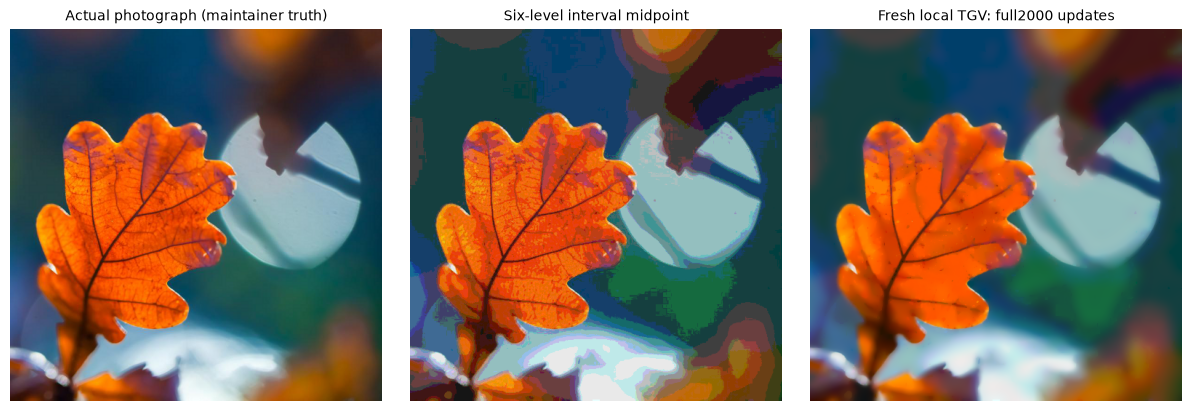

In [2]:
timings={};fresh={};states={}
for method in ['tv','tgv']:
    start=time.perf_counter()
    fresh[method],states[method]=reconstruct_tensor(lower,upper,method=method,device=device,return_state=True)
    timings[method]=time.perf_counter()-start
    numbers['fresh_'+method]=fresh[method]
rows={name:metrics(image,truth,lower,upper) for name,image in {'midpoint':midpoint,'original_tv':original['tv'],'original_tgv':original['tgv'],'fresh_tv':fresh['tv'],'fresh_tgv':fresh['tgv'],'independent_standard_cpu':standard_cpu}.items()}
print(json.dumps({'measured_runtime_seconds':timings,'metrics_vs_actual_photo':rows},indent=2))
show(image_panel([truth,midpoint,fresh['tgv']],['Actual photograph (maintainer truth)','Six-level interval midpoint','Fresh local TGV: full2000 updates']), '01_observation_and_reconstruction')


## 5. Results

The next panels compare every method against the same pre-quantization photograph, without alignment, gain fitting, crop-based scoring or color-space conversion. NRMSE is RMS error divided by the truth's dynamic range. NCC is uncentered cosine similarity. PSNR uses unit peak intensity. Detail crops are display-only; every metric uses the full native RGB image.

The CPU standard output below was computed by the independently executed standard CLI. It is an explicitly labeled additional numerical comparison; the fresh notebook reconstruction is the new tensor result computed above.

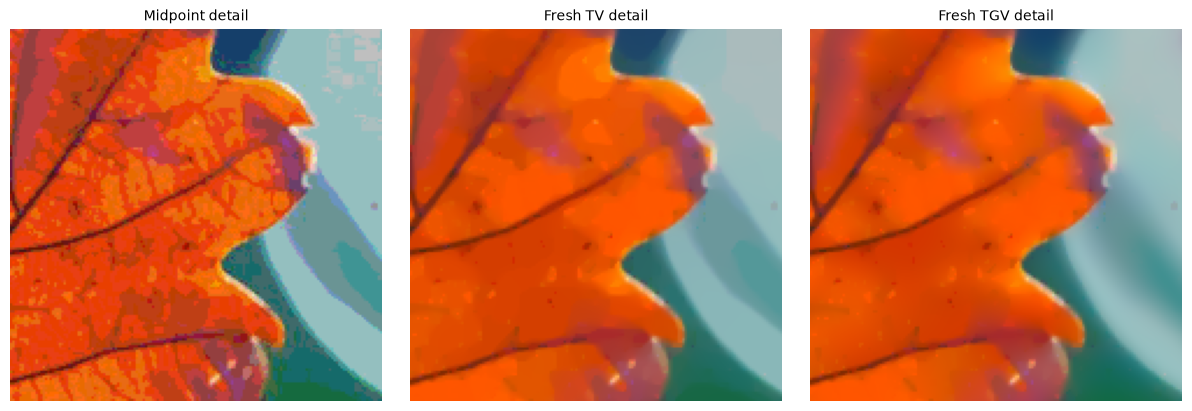

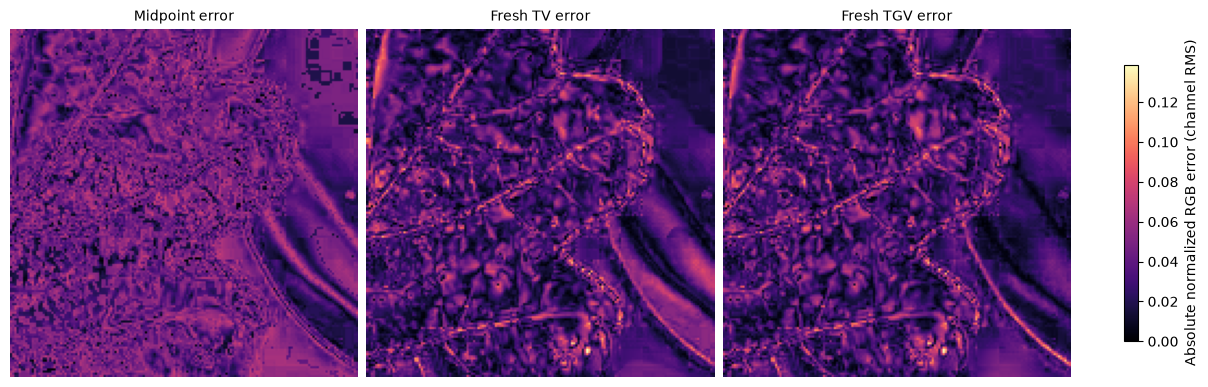

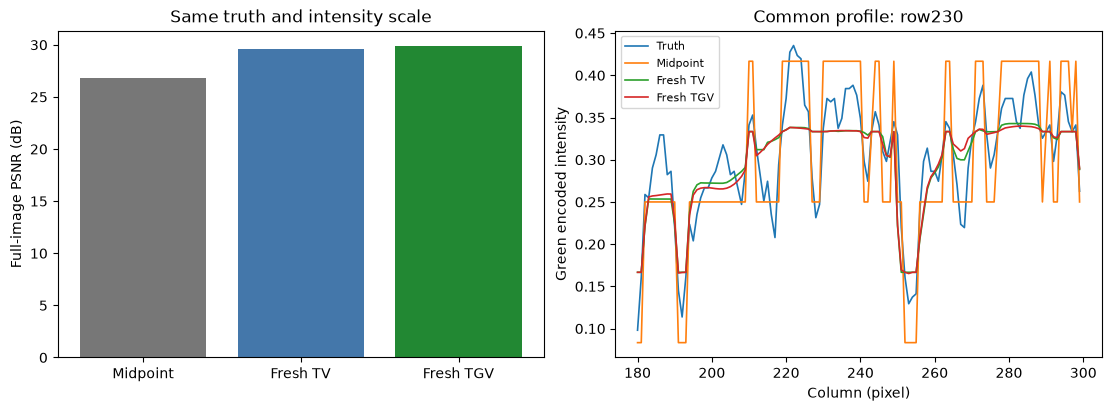

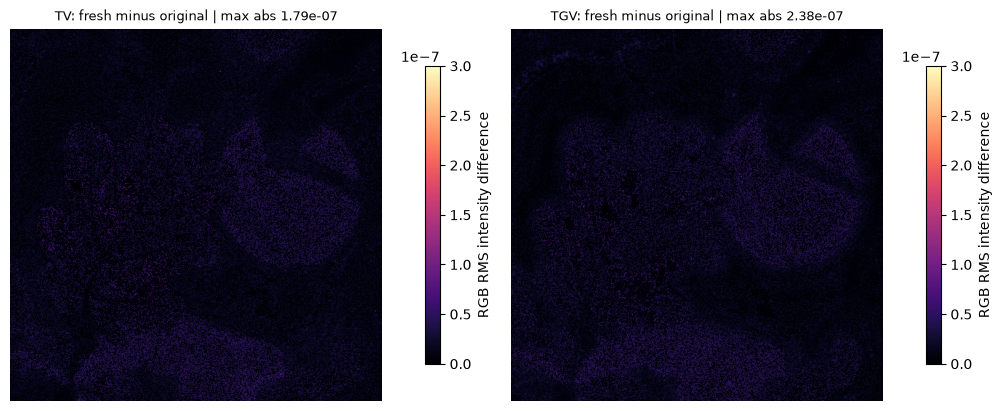

{
  "tv": 1.7881393432617188e-07,
  "tgv": 2.384185791015625e-07,
  "standard_cpu_vs_original_tgv": 2.086162567138672e-07
}


In [3]:
region=np.s_[160:320,180:340,:]
images=[midpoint[region],fresh['tv'][region],fresh['tgv'][region]]
errors=[np.sqrt(np.mean((a[region].astype(float)-truth[region])**2,axis=-1)) for a in [midpoint,fresh['tv'],fresh['tgv']]]
show(image_panel(images,['Midpoint detail','Fresh TV detail','Fresh TGV detail']), '02_detail_comparison')
show(image_panel(errors,['Midpoint error','Fresh TV error','Fresh TGV error'],error=True,vmax=max(float(a.max()) for a in errors)), '03_common_scale_errors')
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
names=['midpoint','fresh_tv','fresh_tgv'];xs=np.arange(3)
axs[0].bar(xs,[rows[n]['psnr_db'] for n in names],color=['#777777','#4477aa','#228833']);axs[0].set_xticks(xs,['Midpoint','Fresh TV','Fresh TGV']);axs[0].set_ylabel('Full-image PSNR (dB)');axs[0].set_title('Same truth and intensity scale')
row=230;channel=1
for name,image in [('Truth',truth),('Midpoint',midpoint),('Fresh TV',fresh['tv']),('Fresh TGV',fresh['tgv'])]:axs[1].plot(np.arange(180,300),image[row,180:300,channel],label=name,lw=1.2)
axs[1].set(xlabel='Column (pixel)',ylabel='Green encoded intensity',title='Common profile: row230');axs[1].legend(fontsize=8)
show(fig,'04_accuracy_and_profile')
parity={method:float(np.max(np.abs(fresh[method]-original[method]))) for method in fresh}
parity['standard_cpu_vs_original_tgv']=float(np.max(np.abs(standard_cpu-original['tgv'])))
fig,axs=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for ax,method in zip(axs,['tv','tgv']):
    im=ax.imshow(np.sqrt(np.mean((fresh[method].astype(float)-original[method])**2,axis=-1)),vmin=0,vmax=3e-7,cmap='magma');ax.set_title(f'{method.upper()}: fresh minus original | max abs {parity[method]:.3g}',fontsize=9);ax.set_axis_off();fig.colorbar(im,ax=ax,label='RGB RMS intensity difference',shrink=.8)
show(fig,'05_original_source_parity');print(json.dumps(parity,indent=2))


### Full original parameter comparison

The source tests eleven weights from0.40 to0.50 for both TV and TGV. We actively run those same22 complete native2000-update reconstructions. The original example notebook's TV0.49 setting is included in this scan; the earlier paired panels use the same0.45 weight for both families to distinguish that controlled comparison from the source's separately chosen example weights. Truth-based curves are a maintainer sensitivity diagnostic, not a solver input or a rule for tuning the standard0.45 choice. Every plotted point has an actual reconstruction and measured time; no archived curve or zero stand-in is used.

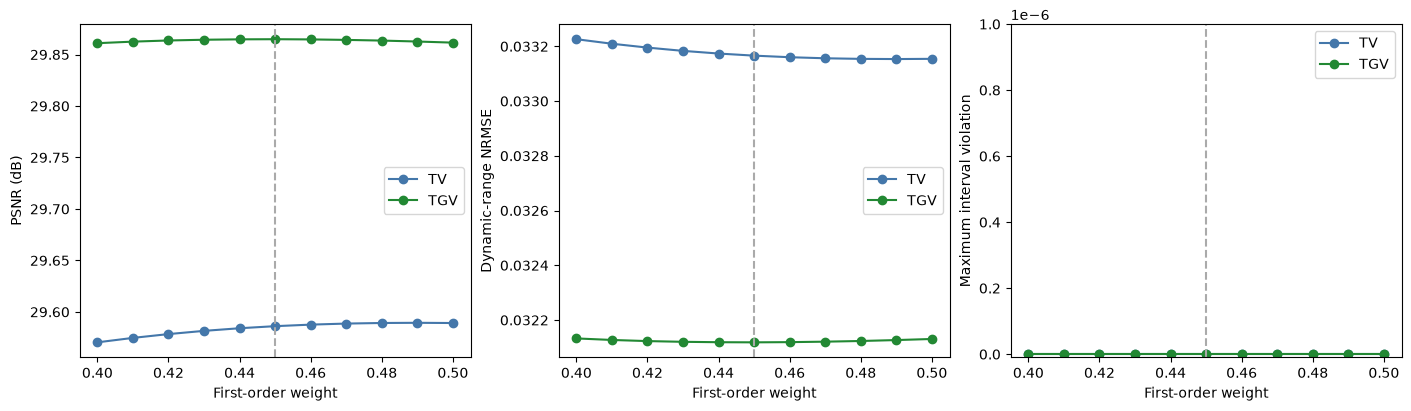

{
  "tv": [
    {
      "ncc": 0.9973269620805041,
      "nrmse": 0.0332260152206052,
      "psnr_db": 29.570434806367807,
      "interval_violation": 0.0,
      "alpha": 0.4,
      "runtime_seconds": 2.358212699997239
    },
    {
      "ncc": 0.9973297450260912,
      "nrmse": 0.033209492503451205,
      "psnr_db": 29.57475522192858,
      "interval_violation": 0.0,
      "alpha": 0.41000000000000003,
      "runtime_seconds": 2.355558600000222
    },
    {
      "ncc": 0.9973321536488821,
      "nrmse": 0.03319537340228548,
      "psnr_db": 29.57844883548203,
      "interval_violation": 0.0,
      "alpha": 0.42000000000000004,
      "runtime_seconds": 2.356432999993558
    },
    {
      "ncc": 0.9973342273795097,
      "nrmse": 0.033183415252114094,
      "psnr_db": 29.581578364534703,
      "interval_violation": 0.0,
      "alpha": 0.43,
      "runtime_seconds": 2.3689118000038434
    },
    {
      "ncc": 0.9973359590370712,
      "nrmse": 0.03317366253559722,
      "psnr_db": 29.

In [4]:
alphas=np.linspace(.4,.5,11);scan={};scan_images={}
for method in ['tv','tgv']:
    scan[method]=[];scan_images[method]=[]
    for alpha in alphas:
        start=time.perf_counter();image=reconstruct_tensor(lower,upper,alpha=float(alpha),method=method,device=device)
        record=metrics(image,truth,lower,upper);record.update(alpha=float(alpha),runtime_seconds=time.perf_counter()-start)
        scan[method].append(record);scan_images[method].append(image)
    numbers['scan_'+method]=np.stack(scan_images[method])
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for method,color in [('tv','#4477aa'),('tgv','#228833')]:
    axs[0].plot(alphas,[r['psnr_db'] for r in scan[method]],'o-',label=method.upper(),color=color)
    axs[1].plot(alphas,[r['nrmse'] for r in scan[method]],'o-',label=method.upper(),color=color)
    axs[2].plot(alphas,[r['interval_violation'] for r in scan[method]],'o-',label=method.upper(),color=color)
for ax in axs:ax.set_xlabel('First-order weight');ax.axvline(.45,color='#aaaaaa',ls='--');ax.legend()
axs[0].set_ylabel('PSNR (dB)');axs[1].set_ylabel('Dynamic-range NRMSE');axs[2].set_ylabel('Maximum interval violation');axs[2].set_ylim(-1e-8,1e-6)
show(fig,'06_full_parameter_scan');print(json.dumps(scan,indent=2))


### Regularizer and acquisition checks

The first-order TGV mismatch and the auxiliary shading field diagnose what the method penalizes. Gradients of a globally affine image vanish only in the interior under this zero-outgoing boundary convention; boundary effects remain. The physical consistency check is direct interval membership, independent of any photograph reference. A numerically matching method is not proof that all lost detail is recovered.

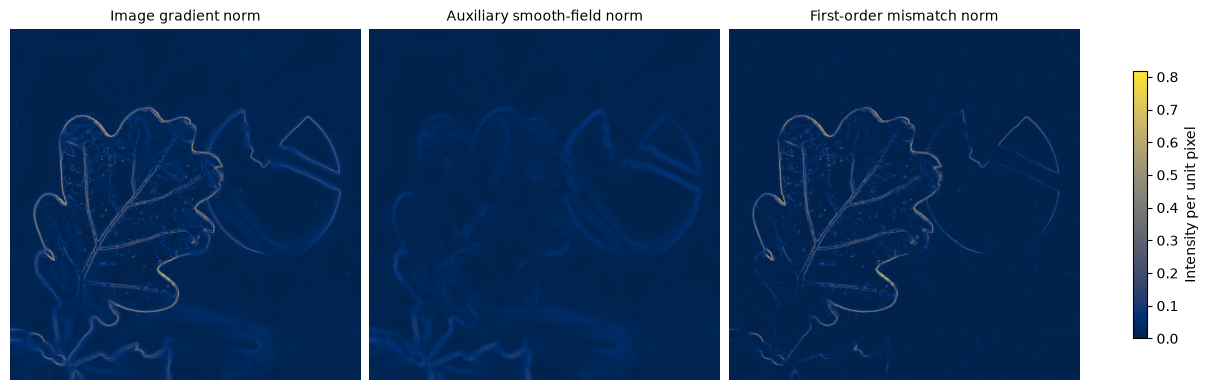

Full native fresh reconstruction, all22 scan paths, interval and original parity checks completed.


In [5]:
w=states['tgv']['w'].reshape(*lower.shape,2)
g=gradient(fresh['tgv']);components=[vector_norm(g),vector_norm(w),vector_norm(g-w)]
fig,axs=plt.subplots(1,3,figsize=(12,4),layout='constrained');vmax=max(float(x.max()) for x in components)
for ax,image,title in zip(axs,components,['Image gradient norm','Auxiliary smooth-field norm','First-order mismatch norm']):
    im=ax.imshow(image,cmap='cividis',vmin=0,vmax=vmax);ax.set_title(title,fontsize=10);ax.set_axis_off()
fig.colorbar(im,ax=list(axs),label='Intensity per unit pixel',shrink=.7);show(fig,'07_regularizer_decomposition')
assert max(r['interval_violation'] for method in scan.values() for r in method)<=1e-6
assert max(parity.values())<3e-6
assert rows['fresh_tgv']['nrmse']<rows['midpoint']['nrmse']
print('Full native fresh reconstruction, all22 scan paths, interval and original parity checks completed.')
archive=os.environ.get('IMAGING101_REVIEW_ARCHIVE')
if archive:
    out=Path(archive);out.mkdir(parents=True,exist_ok=True)
    for name,fig in figures:
        for suffix in ['png','svg','pdf']:fig.savefig(out/(name+'.'+suffix),dpi=160,bbox_inches='tight')
    np.savez_compressed(out/'numerical_sources.npz',**numbers)
    (out/'measurements.json').write_text(json.dumps({'rows':rows,'runtime_seconds':timings,'parity_max_abs':parity,'scan':scan,'python':sys.executable,'device':device},indent=2,allow_nan=False),encoding='utf8')


## 6. Conclusion

Both local TV and TGV recover within-bin shading while respecting the observed intervals. Full-image truth metrics, matched detail crops and the22-run sensitivity scan make their differences assessable. Independent original-stage fixtures and the separately executed CPU path agree at float32 numerical precision.

This is a controlled simulated-acquisition task using a real author-provided photograph. It does not demonstrate real low-bit detector recovery or absolute radiometric calibration. TGV is a spatial prior: information erased by quantization remains ambiguous. The chosen fixed iteration budget reproduces the selected source experiment; it is not a general convergence guarantee. All legal, source, environment, data and numerical evidence is indexed in `test/validation.md`.